# E2M3 → E2M1: mantissa-MSB's verwijderen en exponent aanpassen

Deze notebook leest de bestanden van één uitvoering. Numerieke coderegels en gemeten netwerkresultaten worden afzonderlijk getoond. Runstatus en ontbrekende gegevens zijn zichtbaar; eerder gemeten referentieaccuracy wordt nooit als nieuwe meting ingevuld.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown

# Alleen aanpassen als de resultaatmap is verplaatst.
RUN_DIR = None
_GENERATED_OUTPUT = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_mantissa_msb_exponent_probe_v1\\20261113_174123_159210_evaluate')
_candidates = [Path(RUN_DIR).expanduser()] if RUN_DIR is not None else [Path.cwd(), _GENERATED_OUTPUT]
OUT = next((p.resolve() for p in _candidates if (p / 'probe_notebook.py').is_file()
            and any((p / name).is_file() for name in ('run_report.json', 'numeric_summary.json'))), None)
if OUT is None:
    raise FileNotFoundError('Stel RUN_DIR in op de map met run_report.json en probe_notebook.py.')
sys.path.insert(0, str(OUT))
import probe_notebook as view
if Path(view.__file__).resolve() != OUT / 'probe_notebook.py':
    raise RuntimeError('Een helper uit een andere uitvoermap is al geïmporteerd; herstart de kernel.')
results = view.read_results(OUT)
display(Markdown(view.status_markdown(results)))

## Runstatus: PASS

Niet-synthetische uitvoering volgens het runrapport.

| Onderdeel | Waarneming |
| --- | --- |
| Commando | evaluate |
| Netwerkevaluatie bevestigd | ja |
| Numerieke tabel gecontroleerd | ja; 192 CSV-rijen |
| Gemeten netwerkvarianten | 5 |

### Uitgevoerd protocol

```text
{
  "schema": "mx-mantissa-msb-exponent-probe-protocol-v1",
  "stage": "exploratory_numerical_and_posthoc_only",
  "source": "pinned epoch100 compact E4 export from independent E2 scale freeze-after50 run",
  "model": "CNN-8 / svhnq expand=2",
  "activation_bits": 32,
  "block_size": 32,
  "output_format": "standard MX E2M1",
  "mantissa_bit_names": "m2=magnitude 1/2, m1=1/4, m0=1/8 for normal E2M3 elements",
  "lsb_trunc": "retain sign, exponent field E, and m2; delete m1,m0",
  "rne": "nearest E2M1 value to the SAME E2M3 code, ties to even, saturating",
  "msb_bestexp": "retain sign and m0, choose Eprime in 0..3 to minimize absolute source error",
  "msb_ties": "minimize abs(Eprime-E), then choose smallest Eprime",
  "msb_equivalent_bit_rule": "Eprime=min(3,E+int((mantissa&7)==6)); target_mantissa=m0",
  "optimization_scope": "smallest per-element source error under fixed m0; NOT accuracy optimality",
  "shared_scales": "copy existing E2 E8M0 bytes unchanged for all three E2M1 alternatives",
  "bn_policy": "same saved bank4, fixed evaluation mode for every E2M1 alternative; no recalibration",
  "other_modes": "E4 and E2M3 are loaded as unchanged controls",
  "training_performed": false,
  "optimizer_created": false,
  "dataset": "full SVHN official test, no train or extra loading",
  "batch_size": 128,
  "shuffle": false,
  "workers": 0,
  "error_reference": "decoded E2M3 source, not unavailable FP32 master",
  "numerical_population": "uniform code patterns with scale1, not observed weights",
  "accuracy_population": "actual 26032 SVHN test images; only populated after evaluate",
  "hardware_claim": "bit operations described; no measured area, latency or energy",
  "limitations": [
    "Parent weights and BN were trained with LSB truncation; posthoc results do not rule out QAT adaptation.",
    "One selected model and dataset; no general superiority or inferiority claim.",
    "Exponent tie policy is fixed before network evaluation.",
    "No test labels are used to select the conversion rule.",
    "The removed mantissa bits are still needed during conversion.",
    "Inference uses FP32 convolutions with decoded weights; its wall time is not low-bit hardware timing."
  ]
}
```

## Wat deze proef onderzoekt

De bron is E2M3; het doel blijft standaard E2M1 met hetzelfde teken en dezelfde
gedeelde E8M0-schaal. Schrijf de drie fractionele mantissabits als $m_2m_1m_0$.

| Methode | Bewaarde informatie en keuze |
| --- | --- |
| LSB-truncatie | Verwijder $m_1m_0$; behoud $m_2$ en de exponent. |
| RNE | Kies de dichtstbijzijnde E2M1-waarde; bij gelijke afstand de even doelcode. |
| MSB's weg + beste exponent | Verwijder $m_2m_1$; behoud $m_0$ en zoek de beste van vier exponentcodes. |

**Beste exponent** betekent hier de kleinste absolute fout onder de beperking
$m'=m_0$, bij vast teken en vaste schaal. Bij gelijke fout gaat de voorkeur naar
de kleinste exponentwijziging en daarna naar de laagste exponentcode. Het is geen
optimalisatie van netwerkaccuracy en geen verliesvrije overdracht van informatie.

Voor deze volledige codetabel reduceert de zoekprocedure tot de volgende regel,
met $E\in\{0,1,2,3\}$ de **opgeslagen exponentcode** en $m\in\{0,\ldots,7\}$:

$$m'=m\bmod2,\qquad
E'=\begin{cases}\min(E+1,3),&m=6,\\E,&m\ne6.\end{cases}$$

De resultaatcontrole vergelijkt die compacte regel met alle 64 zoekresultaten.
Deze regel kan dus ook de verwijderde bits raadplegen voordat ze worden weggegooid.
De proef meet geen siliciumoppervlakte, energieverbruik of geheugentoegangskosten.

RNE heeft bij deze vaste schaal en hetzelfde doelcodeboek de kleinste absolute
en gekwadrateerde fout per element. Dat voorspelt de netwerkaccuracy niet volledig.

In [2]:
display(Markdown(view.numeric_markdown(results)))

## Numerieke fout bij uniforme codeweging, S = 1

Alle 32 codes met positief teken, inclusief +0, krijgen hetzelfde gewicht. Dit is geen gemeten gewichtsverdeling van het netwerk. MAE is de gemiddelde absolute fout; MSE is de gemiddelde gekwadrateerde fout. De bias hieronder is het gemiddelde van |doel| − |bron|.

| Methode | MAE | MSE | Max. absolute fout | Magnitude-bias | Exact |
| --- | --- | --- | --- | --- | --- |
| LSB-truncatie | 0.375000 | 0.30078125 | 1.500000 | -0.375000 | 8/32 |
| Afronden (RNE) | 0.281250 | 0.19140625 | 1.500000 | -0.125000 | 8/32 |
| MSB's weg + beste exponent | 0.562500 | 0.72265625 | 3.000000 | -0.250000 | 4/32 |

### Vergelijking per broncode

| Methode | Kleinere fout dan LSB | Gelijke fout | Grotere fout | Dalingen in mapping |
| --- | --- | --- | --- | --- |
| LSB-truncatie | 0 | 32 | 0 | 0 |
| Afronden (RNE) | 7 | 25 | 0 | 0 |
| MSB's weg + beste exponent | 4 | 19 | 9 | 12 |

Een daling betekent dat een grotere positieve bronwaarde een kleinere doelwaarde krijgt; er zijn 31 opeenvolgende overgangen tussen de 32 broncodes.

### Expliciete codepopulaties

| Populatie | Methode | Aantal | MAE | MSE |
| --- | --- | --- | --- | --- |
| Alle 64 codes, beide tekens | LSB-truncatie | 64 | 0.375000 | 0.30078125 |
| Alle 64 codes, beide tekens | Afronden (RNE) | 64 | 0.281250 | 0.19140625 |
| Alle 64 codes, beide tekens | MSB's weg + beste exponent | 64 | 0.562500 | 0.72265625 |
| 31 positieve niet-nulcodes | LSB-truncatie | 31 | 0.387097 | 0.31048387 |
| 31 positieve niet-nulcodes | Afronden (RNE) | 31 | 0.290323 | 0.19758065 |
| 31 positieve niet-nulcodes | MSB's weg + beste exponent | 31 | 0.580645 | 0.74596774 |
| 24 positieve normale codes | LSB-truncatie | 24 | 0.437500 | 0.38281250 |
| 24 positieve normale codes | Afronden (RNE) | 24 | 0.333333 | 0.24739583 |
| 24 positieve normale codes | MSB's weg + beste exponent | 24 | 0.666667 | 0.93489583 |

De 64-codepopulatie telt +0 en −0 als twee encoderingen. De exacte breuken staan in numeric_summary.json; de 192 afzonderlijke beslissingen staan in codebook_mapping.csv.

### Controle van de regels

Uitputtende checks over 64 codes: bevestigd. Compacte exponentregel gelijk aan de opgeslagen zoekresultaten: ja.

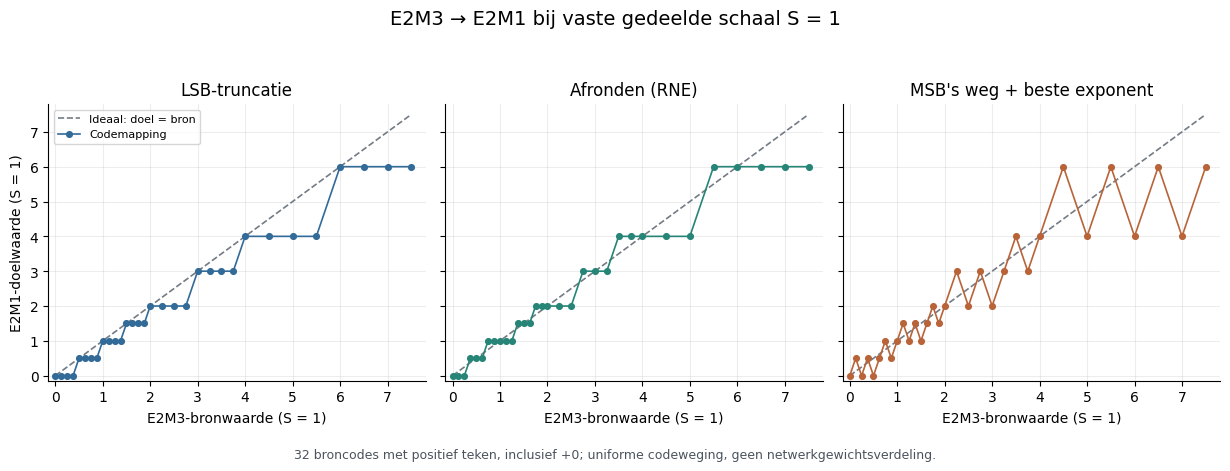

In [3]:
figure = view.plot_numeric(results)
if figure is not None:
    display(figure)
    import matplotlib.pyplot as plt
    plt.close(figure)
else:
    display(Markdown('Geen numerieke figuur: volledige geldige data of optioneel matplotlib ontbreekt.'))

## Gemeten netwerkaccuracy

| Variant | Gewichtsbits | Correct top-1 / n | Top-1 (%) | Top-5 (%) | Verlies |
| --- | --- | --- | --- | --- | --- |
| E4M3-broncontrole | 8 | 24607/26032 | 94.525968 | 99.431469 | 0.201373 |
| E2M3-broncontrole | 6 | 24746/26032 | 95.059926 | 99.477566 | 0.183750 |
| LSB-truncatie | 4 | 24740/26032 | 95.036878 | 99.500615 | 0.186286 |
| Afronden (RNE) | 4 | 23958/26032 | 92.032883 | 99.166411 | 0.323556 |
| MSB's weg + beste exponent | 4 | 23870/26032 | 91.694837 | 99.108789 | 0.331479 |

### Vierbitsvergelijking op dezelfde voorbeelden

| Methode | Verschil correcte voorspellingen versus LSB | Verschil top-1 (procentpunt) |
| --- | --- | --- |
| LSB-truncatie | +0 | +0.000000 |
| Afronden (RNE) | -782 | -3.003995 |
| MSB's weg + beste exponent | -870 | -3.342041 |

### Reproductiecontrole tegenover de bewaarde epoch100-referentie

| Controle | Nu gemeten | Eerdere referentie | Verschil correct |
| --- | --- | --- | --- |
| E4M3-broncontrole | 24607/26032 | 24607/26032 | 0 |
| E2M3-broncontrole | 24746/26032 | 24746/26032 | 0 |
| LSB-truncatie | 24740/26032 | 24740/26032 | 0 |

De referentiewaarden zijn eerder gemeten controles, geen nieuwe metingen. Een afwijking vraagt beoordeling van het runrapport en de uitvoeromgeving.

De vergelijking is beschrijvend voor dit checkpoint en deze testset. Er zijn geen onafhankelijke trainingsherhalingen of statistische significantietoetsen uitgevoerd.

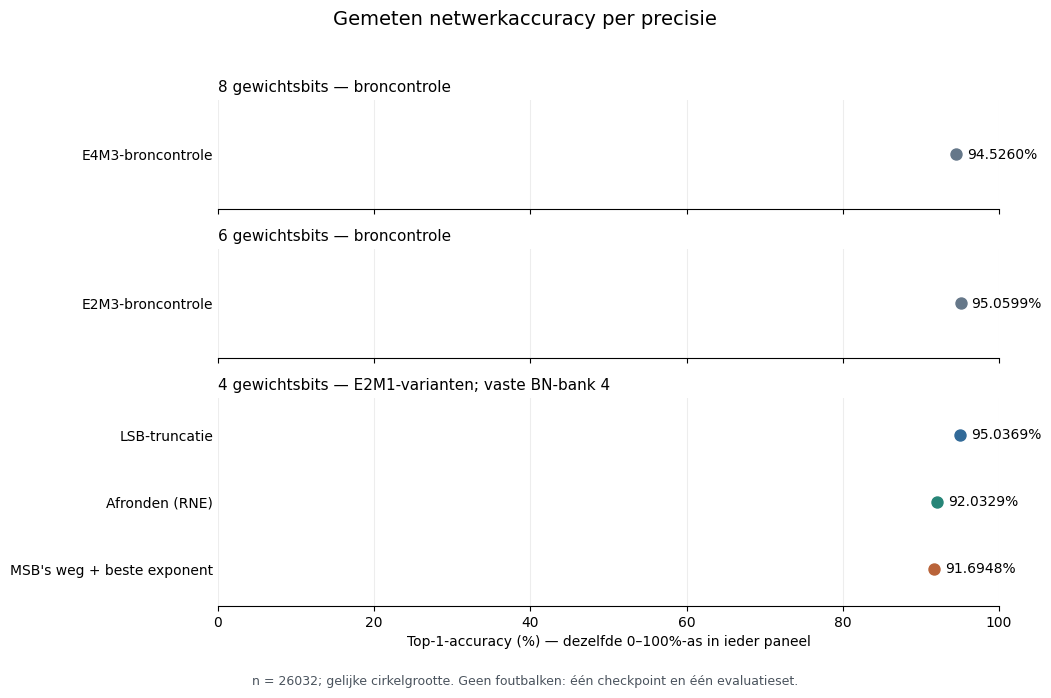

In [4]:
display(Markdown(view.accuracy_markdown(results)))
figure = view.plot_accuracy(results)
if figure is not None:
    display(figure)
    import matplotlib.pyplot as plt
    plt.close(figure)

In [5]:
display(Markdown(view.weight_error_markdown(results)))

## Fout op de werkelijke gewichten

Referentie is de gedecodeerde E2M3-bron, inclusief de opgeslagen schaal per blok. Iedere werkelijke tensorwaarde telt één keer; padding telt niet mee en de gedeelde schaal blijft gelijk. De totalen wegen de zes MX-lagen naar hun aantal gewichten.

| Methode | Gewichten | MAE vs E2M3 | MSE vs E2M3 | Max. absolute fout | Nulwaarden doel | Exponentvelden gewijzigd |
| --- | --- | --- | --- | --- | --- | --- |
| LSB-truncatie | 129472 | 0.00291092 | 1.73544e-05 | 0.0234375 | 264 | 0 |
| Afronden (RNE) | 129472 | 0.00201478 | 7.98353e-06 | 0.0234375 | 184 | 7519 |
| MSB's weg + beste exponent | 129472 | 0.00405982 | 3.06418e-05 | 0.046875 | 213 | 3877 |

### Per MX-laag

| Laag | Methode | Gewichten | MAE vs E2M3 | MSE vs E2M3 |
| --- | --- | --- | --- | --- |
| layers.3 | LSB-truncatie | 1728 | 0.00744685 | 8.68114e-05 |
| layers.3 | Afronden (RNE) | 1728 | 0.00426794 | 2.99541e-05 |
| layers.3 | MSB's weg + beste exponent | 1728 | 0.0070846 | 9.03601e-05 |
| layers.6 | LSB-truncatie | 2304 | 0.00610648 | 5.92427e-05 |
| layers.6 | Afronden (RNE) | 2304 | 0.00349384 | 2.06023e-05 |
| layers.6 | MSB's weg + beste exponent | 2304 | 0.00583861 | 6.0554e-05 |
| layers.10 | LSB-truncatie | 4608 | 0.00680161 | 7.25214e-05 |
| layers.10 | Afronden (RNE) | 4608 | 0.00351249 | 2.03375e-05 |
| layers.10 | MSB's weg + beste exponent | 4608 | 0.00588904 | 6.08248e-05 |
| layers.13 | LSB-truncatie | 9216 | 0.00211716 | 1.02135e-05 |
| layers.13 | Afronden (RNE) | 9216 | 0.00137234 | 4.27485e-06 |
| layers.13 | MSB's weg + beste exponent | 9216 | 0.004147 | 2.74146e-05 |
| layers.16 | LSB-truncatie | 9216 | 0.00284513 | 1.34136e-05 |
| layers.16 | Afronden (RNE) | 9216 | 0.00167317 | 4.72006e-06 |
| layers.16 | MSB's weg + beste exponent | 9216 | 0.00295104 | 1.53974e-05 |
| layers.20 | LSB-truncatie | 102400 | 0.00266476 | 1.37547e-05 |
| layers.20 | Afronden (RNE) | 102400 | 0.00196465 | 7.40042e-06 |
| layers.20 | MSB's weg + beste exponent | 102400 | 0.00397839 | 2.92653e-05 |

De volledige diagnostiek, waaronder RMSE en genormaliseerde MSE, staat in weight_error.csv. Deze fout gebruikt de werkelijke gewichtsverdeling en mag niet worden verward met de uniforme codetabelfout.

## Interpretatie van een eventuele netwerkevaluatie

De netwerkproef gebruikt één bevroren bron uit epoch 100. Alle drie
vierbitsvarianten gebruiken dezelfde opgeslagen E2-schalen en dezelfde BN-bank 4,
die tijdens de training met LSB-truncatie is geleerd. De E4M3- en E2M3-controles
gebruiken respectievelijk hun eigen banken 8 en 32. Activaties blijven A32.

Er wordt niets getraind en er vindt geen BN-herkalibratie plaats. Een verschil
beschrijft daarom het effect van deze posthocvervanging binnen dit checkpoint.
Een slechter resultaat bewijst niet dat dezelfde representatie na aangepaste
quantization-aware training slecht moet presteren. Een beter resultaat bewijst
evenmin een algemene accuracywinst, een optimale trainingsmethode of hardwarewinst.

De numerieke tabellen wegen codes uniform. Gewichtsdiagnostiek, als beschikbaar,
weegt de werkelijk aanwezige tensorwaarden. Testaccuracy telt correcte voorspellingen.
Deze drie grootheden beantwoorden verschillende vragen.

In [6]:
display(Markdown(view.provenance_markdown(results)))

## Herkomst

| Referentiegegeven | Waarde |
| --- | --- |
| Verwachte bron | mx_source_MXFP8_E4M3_last.pt |
| Verwachte epoch | 100 |
| Verwachte bron-SHA256 | 636bececacb8008be40aa341d55abcfdfbc80a7325fe71e6b8cea4947b870f1d |
| Verwachte checkpoint-SHA256 | e824893d0f18b384857086ae9f72c4ad672e5218956e607c2684788c43ddb4a0 |

Dit zijn de bedoelde brongegevens uit het referentiebestand (reference.json, een kopie van pakket-REFERENCE.json). Of een bron werkelijk is geladen en geverifieerd, staat in het uitvoerrapport; een numerieke analyse alleen laadt geen netwerk.

## Optionele uitvoerfiguren

De runner kan PNG-figuren in de submap `figures` plaatsen. De onderstaande optionele stap maakt alleen ontbrekende figuren in deze resultaatmap; CSV- en JSON-invoer blijven ongewijzigd.

In [7]:
SAVE_FIGURES = False
if SAVE_FIGURES:
    for path in view.create_figures(OUT):
        display(Markdown(f'[{path.name}](figures/{path.name})'))